# 03 · Signatures — embryonic module geography & Gate 2

Score the three embryonic modules on the malignant manifold and read **Gate 2**: does the module
pattern appear? For a **non-branching** manifold the criterion (§1–2) is a single developmental axis —
Gast/pSom overlap as the body, Crest an inverse/terminal gradient — which **passes (GO)** with no
bifurcation for Gate 3 (**NA**). We show the **raw** per-cell scores in the deliverable UMAPs (binding;
smoothing aids the analysis but misleads as a deliverable), and read geography from the graph-smoothed
scores carried from 02. Deliverables: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present | global mean {adata.obs[lab].mean():+.3f}')

cells: 10512
Gast: 77/81 genes present | global mean -0.040
pSom: 92/98 genes present | global mean +0.056
Crest: 101/104 genes present | global mean -0.027


### Gate 2 read — module geography
Gast opposite Crest on one axis; pSom overlaps the Gast/body pole. Along pseudotime Gast decays and
Crest rises to a terminal pole (Crest-high decile at high pseudotime). This is the non-branching
developmental axis: **Gate 2 GO**, **Gate 3 NA**. Crest peaks at the terminus (not on a Gast arm), so
no Crest-inversion flag.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('Gate 2: single Gast->Crest developmental axis, Crest terminal -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA  | Crest enriches the terminus, not a Gast arm -> no inversion flag')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.11
  Crest_sm vs Gast_sm: r = -0.55
  Crest_sm vs pSom_sm: r = -0.41
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.545
  pSom_sm: rho = +0.090
  Crest_sm: rho = +0.476
Neural-crest-high decile mean pseudotime = 0.81 (terminal if ~1)
Gate 2: single Gast->Crest developmental axis, Crest terminal -> GO (non-branching)
Gate 3: no bifurcation -> NA  | Crest enriches the terminus, not a Gast arm -> no inversion flag


### Signature UMAPs (deliverables) — raw scores
House style: `figsize=(3.5,1.5)`, `size=30`, `cmap='plasma'`, on the house orientation. **Raw**
per-cell scores are plotted (binding); colorbars span each module's raw range.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


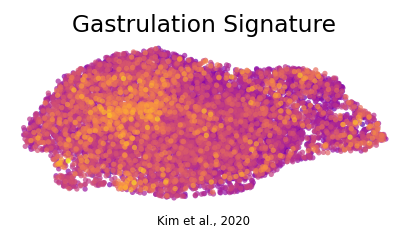

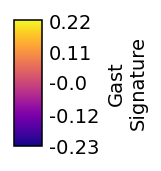

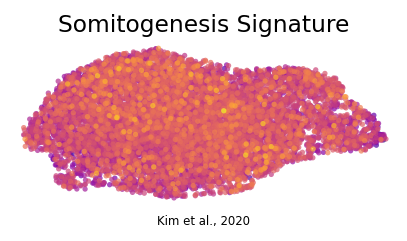

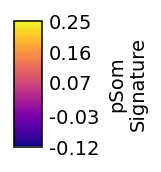

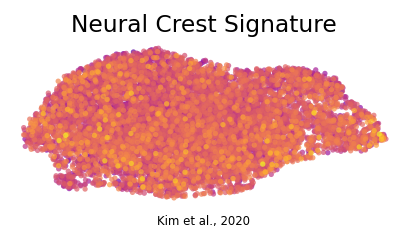

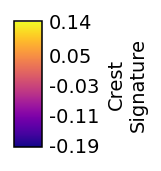

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Kim et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (10512, 18003)
